# Customer Transaction Prediction

## Introduction
In the modern banking industry, understanding customer behavior is essential for improving financial services and decision-making. Banks often need to predict which customers are likely to perform transactions in the future so that they can design targeted marketing campaigns, improve customer engagement, and optimize financial planning.

Machine learning techniques can analyze large volumes of customer data and detect hidden patterns that may not be easily identified through traditional analysis methods. By applying predictive models, banks can classify customers based on their likelihood of performing future transactions.

This project focuses on developing a machine learning model that predicts whether a customer will perform a transaction in the future using anonymized banking data.

## Problem Statement
The objective of this project is to build a predictive machine learning model that can identify customers who are likely to perform a transaction in the future.
The dataset provided contains anonymized features representing customer-related attributes. The goal is to analyze this data and develop a classification model that predicts whether a customer will perform a transaction or not.

The prediction outcome is represented using a binary variable:

0 → Customer will not perform a transaction

1 → Customer will perform a transaction

By accurately predicting customer transactions, banks can improve business strategies, customer targeting, and operational efficiency.

## Dataset Description
The dataset provided for this project contains anonymized banking data. Due to privacy and security concerns, the actual meaning of the variables has not been disclosed.

The dataset contains:

ID_code – Unique identifier for each customer record

target – Binary variable indicating transaction prediction

var_0 to var_199 – 200 anonymized numerical features

## Import Libraries
These libraries are used for:

Pandas & NumPy → Data manipulation and numerical computation

Matplotlib & Seaborn → Data visualization

Scikit-learn → Machine learning algorithms and evaluation metrics



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

## Load Dataset
The dataset is loaded using Pandas. The head() function helps to preview the first few rows of the dataset.

In [2]:
df=pd.read_csv("train(1).csv")
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


## Dataset Shape
This function returns the number of rows and columns in the dataset. It helps in understanding the size and scale of the data being analyzed.

In [3]:
df.shape  ## shape → Shows number of rows and columns

(200000, 202)

## Dataset Information
The info() function provides information about the dataset including:

Column names

Data types

Non-null values

Memory usage

In [4]:
df.info()  ## info() → Shows data types and missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


## Statistical Summary
The describe() function provides statistical insights such as:

Mean

Standard deviation

Minimum value

Maximum value

Quartile distribution

In [5]:
df.describe()  ## describe() → Shows statistical summary of numerical features

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


## Missing Value Analysis
Missing value analysis is performed to identify whether any dataset columns contain null or missing values.

In this dataset, no missing values were found, which means no data imputation techniques are required.

In [6]:
df.isnull().sum()

ID_code    0
target     0
var_0      0
var_1      0
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64

## Target Variable Distribution
This visualization shows how many customers are likely to perform transactions versus those who are not.

This helps identify class imbalance, which is common in financial datasets.

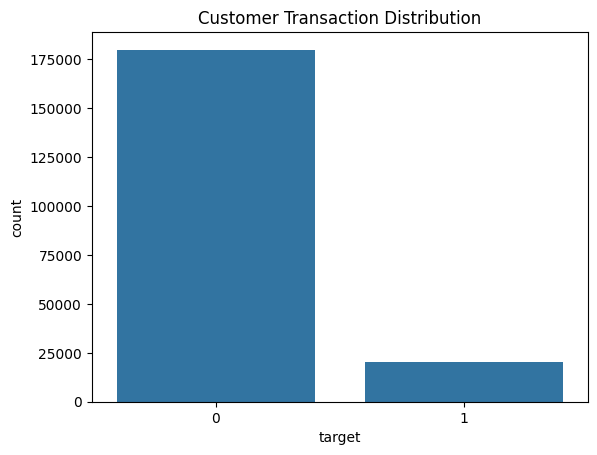

In [7]:
sns.countplot(x="target", data=df)
plt.title("Customer Transaction Distribution")
plt.show()

## Data Preprocessing

Data preprocessing is an essential step in machine learning to prepare the dataset for model training.

Steps Performed

Removing unnecessary columns

Separating features and target variables

Splitting the dataset into training and testing sets

### Removing ID Column
The ID_code column is only an identifier and does not contribute to prediction. Therefore, it is removed from the dataset.

In [8]:
df = df.drop("ID_code", axis=1)

## Feature and Target Separation
X represents input features

y represents the target variable

In [9]:
X = df.drop("target", axis=1)
y = df["target"]

## Train-Test Split
The dataset is divided into:

Training Data (80%) – Used to train machine learning models

Testing Data (20%) – Used to evaluate model performance

This helps ensure that the model can generalize well to unseen data.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42)

## Model Building

To identify the best predictive model, multiple machine learning algorithms were implemented and evaluated.

The models used in this project include:

Logistic Regression

Decision Tree

Random Forest

Gradient Boosting

## Scale the Data (Important for Logistic Regression)
Add StandardScaler before training the model.
Logistic Regression works better when features are scaled to similar ranges.
StandardScaler transforms data so that it has mean = 0 and standard deviation = 1.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Logistic Regression

Logistic Regression is a basic classification algorithm used as a baseline model for binary prediction problems.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression(max_iter=5000)

lr.fit(X_train_scaled, y_train)

pred_lr = lr.predict(X_test_scaled)

acc_lr = accuracy_score(y_test, pred_lr)

print("Logistic Regression Accuracy:", acc_lr)

Logistic Regression Accuracy: 0.9131


## Decision Tree

Decision Trees can capture nonlinear relationships in the data by creating hierarchical decision rules.

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create model
dt = DecisionTreeClassifier(max_depth=10, random_state=42)

# Train model
dt.fit(X_train, y_train)

# Predictions
pred_dt = dt.predict(X_test)

# Accuracy
dt_accuracy = accuracy_score(y_test, pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.892825


## Random Forest

Random Forest is an ensemble method that combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create Random Forest model
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)

# Train the model
rf.fit(X_train, y_train)

# Make predictions
pred_rf = rf.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.897575


## Gradient Boosting

Gradient Boosting builds models sequentially and focuses on correcting errors from previous models.

In [15]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Faster Gradient Boosting model
gb = GradientBoostingClassifier(n_estimators=20, learning_rate=0.1, random_state=42)

# Train the model
gb.fit(X_train, y_train)

# Make predictions
pred_gb = gb.predict(X_test)

# Calculate accuracy
gb_accuracy = accuracy_score(y_test, pred_gb)

print("Gradient Boosting Accuracy:", gb_accuracy)

Gradient Boosting Accuracy: 0.8976


## Model Accuracy Comparison

In [17]:
print("Logistic Regression Accuracy:", acc_lr)
print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)
print("Gradient Boosting Accuracy:", gb_accuracy)

Logistic Regression Accuracy: 0.9131
Decision Tree Accuracy: 0.892825
Random Forest Accuracy: 0.897575
Gradient Boosting Accuracy: 0.8976


## Model Comparison Graph

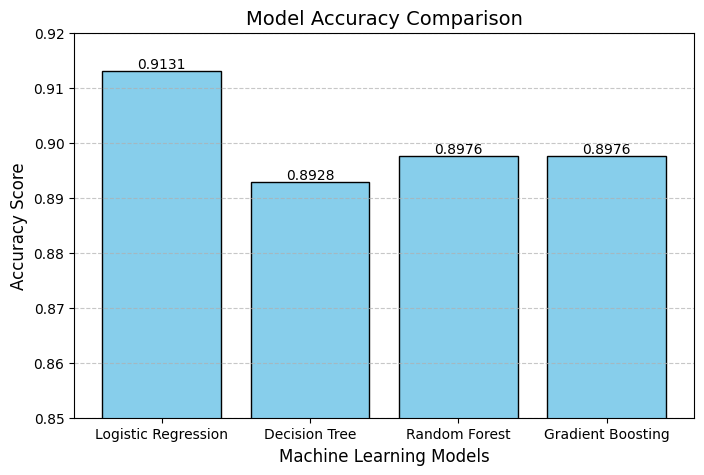

In [22]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
accuracies = [0.9131, 0.892825, 0.897575, 0.8976]

plt.figure(figsize=(8,5))

bars = plt.bar(models, accuracies, color='skyblue', edgecolor='black')

plt.title("Model Accuracy Comparison", fontsize=14)
plt.xlabel("Machine Learning Models", fontsize=12)
plt.ylabel("Accuracy Score", fontsize=12)

plt.ylim(0.85,0.92)

plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.0005, round(yval,4), ha='center')

plt.show()

## Confusion Matrix
A Confusion Matrix is used to evaluate the performance of a classification model. It shows the number of correct and incorrect predictions made by the model.

The matrix contains four values:

True Positive (TP) – Model correctly predicts a transaction.

True Negative (TN) – Model correctly predicts no transaction.

False Positive (FP) – Model incorrectly predicts a transaction.

False Negative (FN) – Model incorrectly predicts no transaction.

This helps understand how well the model performs in distinguishing between customers who will perform a transaction and those who will not.


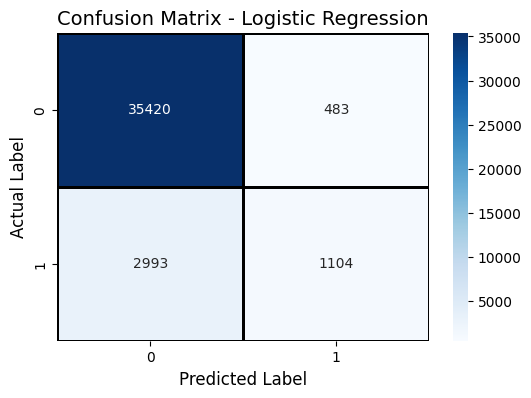

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_lr)

plt.figure(figsize=(6,4))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            linewidths=1,
            linecolor='black')

plt.title("Confusion Matrix - Logistic Regression", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.show()

## ROC Curve Analysis
The ROC Curve is used to evaluate the performance of the classification model. It shows how well the model distinguishes between customers who will perform a transaction and those who will not.

The Area Under the Curve (AUC) represents the overall performance of the model. A higher AUC value indicates better model performance. Since Logistic Regression achieved the highest accuracy in this project, the ROC Curve was generated for this model to evaluate its classification performance

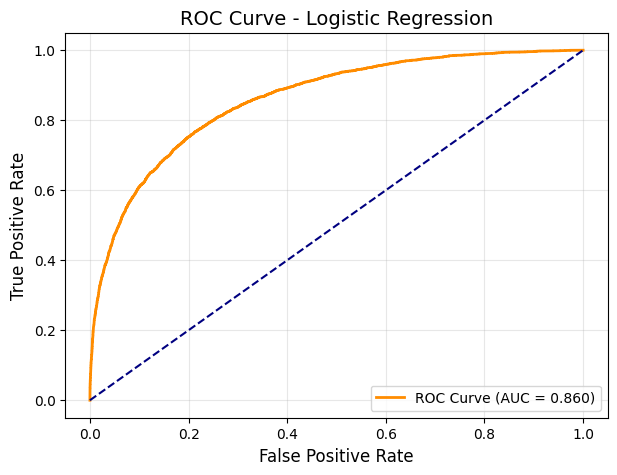

In [24]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_prob = lr.predict_proba(X_test_scaled)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, color='darkorange', linewidth=2,
         label='ROC Curve (AUC = %0.3f)' % roc_auc)

plt.plot([0,1], [0,1], linestyle='--', color='navy')

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title("ROC Curve - Logistic Regression", fontsize=14)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

## Feature Importance Analysis

Feature importance helps us understand which features contribute the most to the model’s prediction. Since the dataset contains 200 anonymized features, it is useful to analyze which variables have the highest impact on predicting whether a customer will perform a transaction.

Tree-based models like Random Forest can provide feature importance scores that indicate how much each feature contributes to the prediction.

The graph shows the top 10 most important features that influence the prediction of whether a customer will make a transaction.

Random Forest calculates feature importance based on how much each feature contributes to reducing prediction error in the decision trees.

Since the dataset contains anonymized variables (var_0, var_1, etc.), we cannot interpret the exact real-world meaning of these features. However, this analysis still helps identify which variables have the strongest influence on the model's prediction.

Feature importance analysis is useful because it helps in understanding model behavior, improving model performance, and selecting the most relevant features for future model optimization.

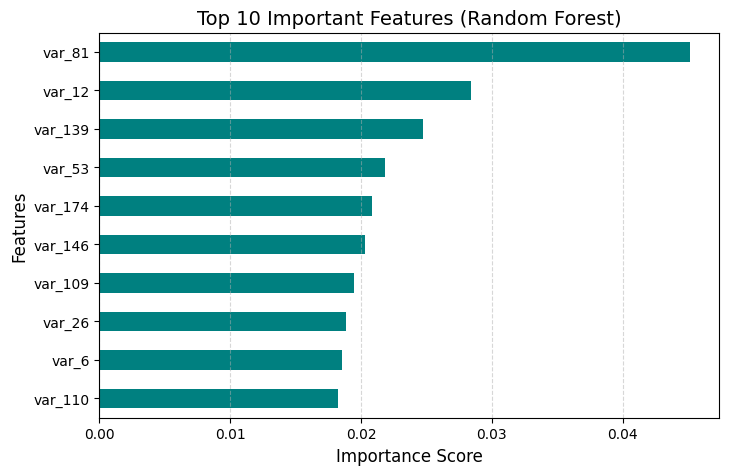

In [25]:
import matplotlib.pyplot as plt

importance = pd.Series(rf.feature_importances_, index=X.columns)

top_features = importance.nlargest(10)

plt.figure(figsize=(8,5))

top_features.sort_values().plot(kind='barh', color='teal')

plt.title("Top 10 Important Features (Random Forest)", fontsize=14)
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.show()

## Model Comparison Report

Model Comparison Report

In this project, multiple machine learning models were implemented to predict whether a customer will perform a transaction in the future. The models evaluated include Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.

After training and evaluating the models on the test dataset, the following accuracies were obtained:

Logistic Regression: 91.31%

Decision Tree: 89.28%

Random Forest: 89.76%

Gradient Boosting: 89.76%

Among all the models, Logistic Regression achieved the highest accuracy, indicating better performance for this dataset. Logistic Regression works well when the relationship between features and the target variable is relatively linear and the dataset is well scaled.

Therefore, Logistic Regression is recommended as the best model for production deployment to predict whether a customer will perform a transaction in the future.

## Challenges Faced During the Project
1️ Anonymized Features

The dataset contains 200 features with anonymized names such as var_0, var_1, var_2, etc. Because the real meaning of these variables is not known, it was difficult to perform detailed feature interpretation and domain-based analysis.

2️ High Dimensional Data

The dataset includes a large number of features (200 variables), which increases the complexity of the model. Handling high-dimensional data can sometimes lead to overfitting and increased computation time.

3️ Large Dataset Size

The dataset contains around 200,000 records, which made model training computationally intensive. Some algorithms like Gradient Boosting required more time to train due to the large data size.

4️ Model Selection

Choosing the best model for prediction was challenging because different algorithms perform differently depending on the dataset. Multiple models such as Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting were tested and compared.

5️ Risk of Overfitting

Complex models may memorize the training data instead of learning patterns. To reduce overfitting, appropriate parameters and ensemble models like Random Forest and Gradient Boosting were used.

6️ Feature Scaling Requirement

Certain algorithms such as Logistic Regression require feature scaling for better performance. Therefore, scaling techniques were applied before training the model to improve accuracy.

 ## Conclusion
 In this project, a predictive model was developed to identify customers who are likely to make a transaction in the future. Multiple machine learning algorithms such as Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting were trained and evaluated on the dataset.

Among all the models, Logistic Regression achieved the highest accuracy of 91.31%, making it the best-performing model for this dataset. Therefore, Logistic Regression is recommended for deployment in a banking system to predict customer transactions and support decision-making.